In [ ]:
library(ggplot2)

data(diamonds)

head(diamonds)
str(diamonds)
summary(diamonds)

carat,cut,color,clarity,depth,table,price,x,y,z
<dbl>,<ord>,<ord>,<ord>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
0.23,Ideal,E,SI2,61.5,55,326,3.95,3.98,2.43
0.21,Premium,E,SI1,59.8,61,326,3.89,3.84,2.31
0.23,Good,E,VS1,56.9,65,327,4.05,4.07,2.31
0.29,Premium,I,VS2,62.4,58,334,4.20,4.23,2.63
0.31,Good,J,SI2,63.3,58,335,4.34,4.35,2.75
0.24,Very Good,J,VVS2,62.8,57,336,3.94,3.96,2.48


tibble [53,940 × 10] (S3: tbl_df/tbl/data.frame)
 $ carat  : num [1:53940] 0.23 0.21 0.23 0.29 0.31 0.24 0.24 0.26 0.22 0.23 ...
 $ cut    : Ord.factor w/ 5 levels "Fair"<"Good"<..: 5 4 2 4 2 3 3 3 1 3 ...
 $ color  : Ord.factor w/ 7 levels "D"<"E"<"F"<"G"<..: 2 2 2 6 7 7 6 5 2 5 ...
 $ clarity: Ord.factor w/ 8 levels "I1"<"SI2"<"SI1"<..: 2 3 5 4 2 6 7 3 4 5 ...
 $ depth  : num [1:53940] 61.5 59.8 56.9 62.4 63.3 62.8 62.3 61.9 65.1 59.4 ...
 $ table  : num [1:53940] 55 61 65 58 58 57 57 55 61 61 ...
 $ price  : int [1:53940] 326 326 327 334 335 336 336 337 337 338 ...
 $ x      : num [1:53940] 3.95 3.89 4.05 4.2 4.34 3.94 3.95 4.07 3.87 4 ...
 $ y      : num [1:53940] 3.98 3.84 4.07 4.23 4.35 3.96 3.98 4.11 3.78 4.05 ...
 $ z      : num [1:53940] 2.43 2.31 2.31 2.63 2.75 2.48 2.47 2.53 2.49 2.39 ...


     carat               cut        color        clarity          depth      
 Min.   :0.2000   Fair     : 1610   D: 6775   SI1    :13065   Min.   :43.00  
 1st Qu.:0.4000   Good     : 4906   E: 9797   VS2    :12258   1st Qu.:61.00  
 Median :0.7000   Very Good:12082   F: 9542   SI2    : 9194   Median :61.80  
 Mean   :0.7979   Premium  :13791   G:11292   VS1    : 8171   Mean   :61.75  
 3rd Qu.:1.0400   Ideal    :21551   H: 8304   VVS2   : 5066   3rd Qu.:62.50  
 Max.   :5.0100                     I: 5422   VVS1   : 3655   Max.   :79.00  
                                    J: 2808   (Other): 2531                  
     table           price             x                y         
 Min.   :43.00   Min.   :  326   Min.   : 0.000   Min.   : 0.000  
 1st Qu.:56.00   1st Qu.:  950   1st Qu.: 4.710   1st Qu.: 4.720  
 Median :57.00   Median : 2401   Median : 5.700   Median : 5.710  
 Mean   :57.46   Mean   : 3933   Mean   : 5.731   Mean   : 5.735  
 3rd Qu.:59.00   3rd Qu.: 5324   3rd Qu.:



```
# This is formatted as code
```
1. How many observations and variables are contained in the dataset?

Asnwer: The dimonds dataset contains 53,940 observations with 10 variables.

2. Identify the response variable and explain what it measures.

Answer: The response variable is the price, which measures the price of diamond in US dollars.

3. Identify the quantitative explanatory variable used i n this assessment and describe its measurement.

Answer: The quantitative explanatory variable is  carat, which measures the weight of the diamond.

4. Identify the categorical explanatory variable and list its five categories.

Answer: The categorical explanatory is cut. The five categories includes fair, good, very good, premium, and ideal.

5. Select one category of cut as the reference category and explain why a reference category is necessary when using dummy variables.

In [ ]:
library(ggplot2)

data(diamonds)
diamonds$cut <-factor(diamonds$cut, ordered = "FALSE")

diamonds$cut <-relevel(diamonds$cut, ref = "Ideal")

contrasts(diamonds$cut)

,Fair,Good,Very Good,Premium
Ideal,0,0,0,0
Fair,1,0,0,0
Good,0,1,0,0
Very Good,0,0,1,0
Premium,0,0,0,1


2. Explain what the all-zero category represents.

Answer: The all zero caterogy is Ideal, which is the reference group with value of 0 for all dummy variables that serves as a baseline.

3. Explain why five dummy variables should not be included togetger with an intercept.

Answer: The five dummy variables including the Ideal, Fair, Good, Very Good, and Premium should not be included with an intercept because one must be left out as a reference group. Since the dummy variables always sum to 1.

In [ ]:
model1<- lm(price ~ carat + cut, data =  diamonds)

summary(model1)


Call:
lm(formula = price ~ carat + cut, data = diamonds)

Residuals:
     Min       1Q   Median       3Q      Max 
-17540.7   -791.6    -37.6    522.1  12721.4 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -2074.55      14.23 -145.77   <2e-16 ***
carat         7871.08      13.98  563.04   <2e-16 ***
cutFair      -1800.92      39.34  -45.77   <2e-16 ***
cutGood       -680.59      24.00  -28.36   <2e-16 ***
cutVery Good  -290.79      17.24  -16.87   <2e-16 ***
cutPremium    -361.85      16.69  -21.68   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1511 on 53934 degrees of freedom
Multiple R-squared:  0.8565,	Adjusted R-squared:  0.8565 
F-statistic: 6.437e+04 on 5 and 53934 DF,  p-value: < 2.2e-16


1. Write the estimated regression equation from the R output.

Answer: The estimated equation is:
Price = - 20074.55 - 7871.08(Carat) - 1800.92(Fair) - 680.59(Good) - 290.79(VeryGoo) - 361.85(Premium)

2. Interpret the coefficient of carat in the context of diamond price.

Answer: The estimated proce of a diamond increases by $7,871.08.

3. Interpret one dummy-variable coefficient relative to the reference category.

Answer: Compared with the Ideal, a Good cut diamond is predicted to have a $680.59 lower.

4. Interpret the R^2 of the model.

Answer:This means that the percentage of 85.65 in idamond price is explained by a carat and cut. While the remaining percentage is due to other factors.

5. Based on the additive model, do the regression lines for the different cut categories have the same slope or different slopes? Explain.

Answer: They have the same slope. As seen in the model, there is no iinteraction between the carat and cut. While the dummy variables only change intercept.

In [ ]:
model2 <- lm(price ~ carat * cut, data = diamonds )

summary(model2)

anova(model1, model2)
anova(model2)


Call:
lm(formula = price ~ carat * cut, data = diamonds)

Residuals:
     Min       1Q   Median       3Q      Max 
-14878.3   -793.0    -23.0    546.3  12706.2 

Coefficients:
                   Estimate Std. Error  t value Pr(>|t|)    
(Intercept)        -2300.37      19.46 -118.234  < 2e-16 ***
carat               8192.39      23.57  347.568  < 2e-16 ***
cutFair              461.30      86.57    5.329 9.93e-08 ***
cutGood             -122.35      49.35   -2.479 0.013170 *  
cutVery Good        -117.29      33.71   -3.479 0.000503 ***
cutPremium           -79.53      32.07   -2.480 0.013155 *  
carat:cutFair      -2267.90      76.05  -29.820  < 2e-16 ***
carat:cutGood       -712.76      52.67  -13.533  < 2e-16 ***
carat:cutVery Good  -256.42      37.89   -6.768 1.32e-11 ***
carat:cutPremium    -384.64      34.18  -11.253  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1498 on 53930 degrees of freedom
Multiple R-squared:  0.859

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,53934,123212493961,NA,NA,NA,NA
2,53930,120989369443,4,2223124519,247.7348,2.89282e-211


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
carat,1,729127440120,729127440120,325002.4612,0.00000e+00
cut,4,6133201436,1533300359,683.4558,0.00000e+00
carat:cut,4,2223124519,555781130,247.7348,2.89282e-211
Residuals,53930,120989369443,2243452,NA,NA


1. State the null and alternatice hypptheses for the overall carat x cut interaction.

Answer: There is no interaction between the carat and cut and the slope are the same for all cut categories. There is an interaction between carat and cut and at least one slope is different.

2. Using the regression output, identify the interaction coeffiecients and their corresponding p-values.

Answer: As observed in the model, all the interaction terms have p-caleus less than 0.05, therefore they are statistically significant to each other.

4. At α = 0.05, state your statistical decision and explain what it means in the context
of diamond prices.  

Answer: We reject the null hypothesis, since the p-value is less than 0.05. This means that the interaction between carat and cut is signficant and the effect of carat in pricing differs depending on its cut.

5. Explain the practical difference between the additive model and the interaction model.

Answer: In the additive model, it assumes that carat has the same effect on price for all cut categories. While, the interaction model allowd the effect of carat on price to be different for each category.


`geom_smooth()` using formula = 'y ~ x'


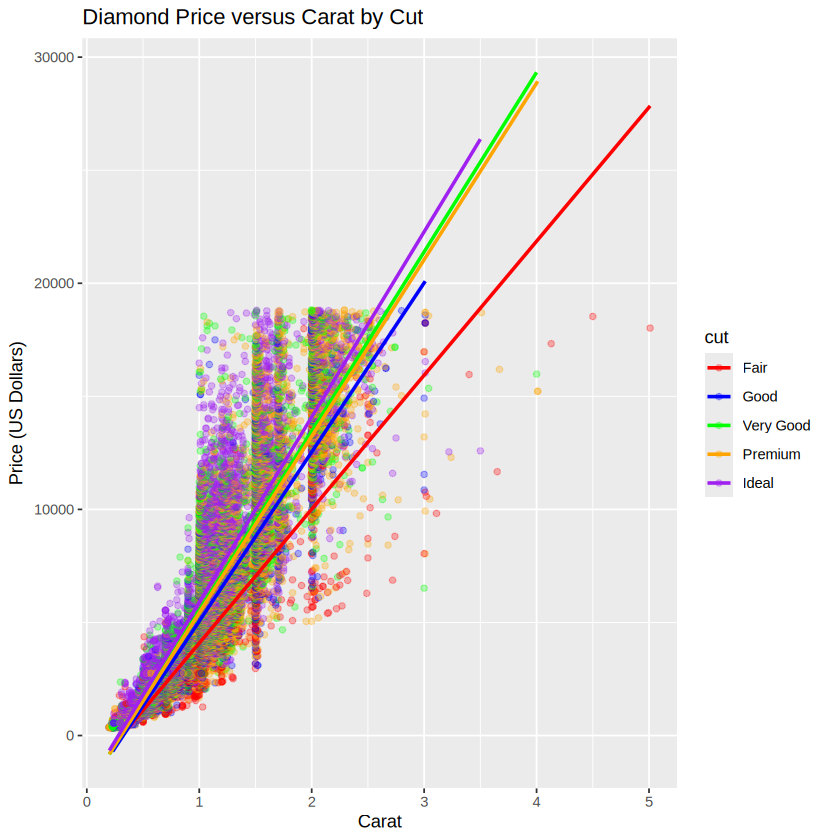

In [ ]:
library(ggplot2)
ggplot(diamonds, aes(x = carat, y = price, color = cut)) +
  geom_point(alpha = 0.3) +
  geom_smooth(method = "lm", se = FALSE) +
  scale_color_manual(values = c("red", "blue", "green", "orange", "purple")) +
  labs(
    title = "Diamond Price versus Carat by Cut",
    x = "Carat",
    y = "Price (US Dollars)"
  )

The regression analysis shows that there is a positive relationship between the carat and price, this means that diamonds become more expensive as carat increases. Also, the cut of the diamond also affects its price, since different cut have also different price levels. The effect of carat can also differ among the different cut of categories, meaning that for every increase in price of a larger carat is not exactly the same for every cut. Overall, both carat and cut are important factors in determining the prices of diamond. So, its pricing not only depends on its size but also on the quality of it.